# 🚦 Smart Urban Transportation Systems
## Exploratory Data Analysis (EDA) – Behavior of the Urban Traffic of São Paulo, Brazil

**Dataset:** UCI Machine Learning Repository, ID 483 (DOI: 10.24432/C5902F, CC BY 4.0)
**Source:** https://archive.ics.uci.edu/dataset/483/behavior+of+the+urban+traffic+of+the+city+of+sao+paulo+in+brazil

---
### How to use this notebook
1. Open in Google Colab (Upload → *File → Upload notebook*).
2. Click **Runtime → Run all**.
3. The notebook downloads the dataset automatically. If the download is blocked, it will ask you to upload the CSV manually (download it from the UCI link above).

### Contents
1. Project overview & problem statement
2. Setup & data loading
3. Initial dataset examination
4. Data cleaning & validation
5. Descriptive statistics
6. Univariate analysis
7. Time-based analysis
8. Incident frequency analysis
9. Relationship analysis (incidents vs. slowness)
10. Correlation analysis
11. Outlier analysis (IQR)
12. Top / bottom observations
13. Bonus: simple predictive baseline
14. Key insights & conclusion

## 1. Project Overview & Problem Statement

Smart Urban Transportation Systems use data from traffic observations, incidents, public transport and sensors to understand mobility and support planning.
This dataset has **135 observations** recorded every **30 minutes from 7:00 AM to 8:00 PM** over **five weekdays (Dec 14–18, 2009)** in São Paulo, with **18 variables** (17 explanatory + 1 target: *Slowness in traffic %*).

**Questions this EDA answers**
- At what times is traffic slowness higher?
- Which incidents occur most frequently?
- Which incidents are associated with higher slowness?
- Are there differences between time periods (and days)?
- Are there outliers / unusual observations?
- Does the dataset need substantial cleaning?

**Intended users:** traffic authorities, urban planners, public transport operators, emergency/municipal services, data scientists, students.

## 2. Setup & Data Loading

In [1]:
import os, io, re, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("Libraries loaded ✅")

Libraries loaded ✅


In [2]:
# ---------- Robust dataset loader ----------
# Order of attempts:
#   1) CSV already present in the working folder (e.g. uploaded by you)
#   2) Direct download of the UCI zip file
#   3) the `ucimlrepo` package
#   4) Manual upload prompt (Colab only)

CSV_NAME = "Behavior of the urban traffic of the city of Sao Paulo in Brazil.csv"
UCI_ZIP  = ("https://archive.ics.uci.edu/static/public/483/"
            "behavior+of+the+urban+traffic+of+the+city+of+sao+paulo+in+brazil.zip")

def read_uci_csv(path_or_buffer):
    # The original file is ';' separated and uses a decimal comma (e.g. 4,1)
    return pd.read_csv(path_or_buffer, sep=";", decimal=",")

def find_local_csv():
    for f in os.listdir("."):
        if f.lower().endswith(".csv") and "sao paulo" in f.lower():
            return f
    return None

def load_dataset():
    # 1) local file
    f = find_local_csv()
    if f:
        print(f"Loaded local file: {f}")
        return read_uci_csv(f)
    # 2) direct download
    try:
        print("Downloading dataset from UCI ...")
        data, _ = urllib.request.urlretrieve(UCI_ZIP, "uci_traffic.zip")
        with zipfile.ZipFile(data) as z:
            name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            with z.open(name) as fh:
                df_ = read_uci_csv(io.TextIOWrapper(fh, encoding="utf-8"))
        print("Downloaded from UCI zip ✅")
        return df_
    except Exception as e:
        print("Direct download failed:", e)
    # 3) ucimlrepo
    try:
        os.system("pip -q install ucimlrepo")
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=483)
        df_ = pd.concat([ds.data.features, ds.data.targets], axis=1)
        print("Loaded via ucimlrepo ✅")
        return df_
    except Exception as e:
        print("ucimlrepo failed:", e)
    # 4) manual upload
    try:
        from google.colab import files
        print("Please upload the CSV downloaded from the UCI page ...")
        up = files.upload()
        return read_uci_csv(io.BytesIO(next(iter(up.values()))))
    except Exception as e:
        raise RuntimeError("Could not load the dataset. Download it from UCI and place the CSV "
                           "next to this notebook.") from e

raw = load_dataset()
df = raw.copy()
print("Raw shape:", df.shape)
df.head()

Downloaded from UCI zip ✅
Raw shape: (135, 18)


,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.1
1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.6
2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.7
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.2
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11.1


## 3. Initial Dataset Examination
We first look at the data exactly as loaded: first/last rows, shape, columns, data types.

In [3]:
print("First five rows"); display(df.head())
print("Last five rows");  display(df.tail())

First five rows


,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.1
1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.6
2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.7
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.2
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11.1


Last five rows


,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
130,23,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,17.8
131,24,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,18.1
132,25,1,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,17.7
133,26,0,4,0,0,0,0,0,0,0,0,0,1,0,0,1,0,17.4
134,27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,12.1


In [4]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
for i, c in enumerate(df.columns, 1):
    print(f"{i:2d}. {c}")

Shape (rows, columns): (135, 18)

Column names:
 1. Hour (Coded)
 2. Immobilized bus
 3. Broken Truck
 4. Vehicle excess
 5. Accident victim
 6. Running over
 7. Fire vehicles
 8. Occurrence involving freight
 9. Incident involving dangerous freight
10. Lack of electricity
11. Fire
12. Point of flooding
13. Manifestations
14. Defect in the network of trolleybuses
15. Tree on the road
16. Semaphore off
17. Intermittent Semaphore
18. Slowness in traffic (%)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Hour (Coded)                           135 non-null    int64  
 1   Immobilized bus                        135 non-null    int64  
 2   Broken Truck                           135 non-null    int64  
 3   Vehicle excess                         135 non-null    int64  
 4   Accident victim                        135 non-null    int64  
 5   Running over                           135 non-null    int64  
 6   Fire vehicles                          135 non-null    int64  
 7   Occurrence involving freight           135 non-null    int64  
 8   Incident involving dangerous freight   135 non-null    int64  
 9   Lack of electricity                    135 non-null    int64  
 10  Fire                                   135 non-null    int64  
 11  Point 

## 4. Data Cleaning & Validation
The UCI documentation reports **no missing values**, so cleaning is *verification-focused*:
- standardize column names,
- make sure every column is numeric (the target uses a decimal comma in the raw file),
- check nulls, duplicates, negative values,
- convert the coded `Hour` into a real clock time and derive the weekday.

In [6]:
# 4.1 Standardize column names
def clean_name(c):
    c = str(c).strip()
    c = c.replace("(%)", "percent").replace("(Coded)", "")
    c = re.sub(r"[^0-9a-zA-Z]+", "_", c).strip("_")
    return c

df.columns = [clean_name(c) for c in df.columns]

# map to the names used in the lab document
rename = {}
for c in df.columns:
    lc = c.lower()
    if lc.startswith("hour"):                rename[c] = "Hour"
    elif lc.startswith("slowness"):          rename[c] = "Slowness_in_traffic_percent"
df = df.rename(columns=rename)
print(list(df.columns))

['Hour', 'Immobilized_bus', 'Broken_Truck', 'Vehicle_excess', 'Accident_victim', 'Running_over', 'Fire_vehicles', 'Occurrence_involving_freight', 'Incident_involving_dangerous_freight', 'Lack_of_electricity', 'Fire', 'Point_of_flooding', 'Manifestations', 'Defect_in_the_network_of_trolleybuses', 'Tree_on_the_road', 'Semaphore_off', 'Intermittent_Semaphore', 'Slowness_in_traffic_percent']


In [7]:
# 4.2 Make sure everything is numeric (handles decimal commas if present)
for c in df.columns:
    if df[c].dtype == object:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")

TARGET = "Slowness_in_traffic_percent"
INCIDENTS = [c for c in df.columns if c not in ("Hour", TARGET)]
print("Target:", TARGET)
print("Number of incident variables:", len(INCIDENTS))
df.dtypes

Target: Slowness_in_traffic_percent
Number of incident variables: 16


,0
Hour,int64
Immobilized_bus,int64
Broken_Truck,int64
Vehicle_excess,int64
Accident_victim,int64
Running_over,int64
Fire_vehicles,int64
Occurrence_involving_freight,int64
Incident_involving_dangerous_freight,int64
Lack_of_electricity,int64


In [8]:
# 4.3 Validation checks
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().any().any() else "None – no missing values ✅")

print("\nDuplicate rows:", df.duplicated().sum())

neg = (df[INCIDENTS + [TARGET]] < 0).sum().sum()
print("Negative values in incident/target columns:", neg)

print("\nHour (coded) range:", df["Hour"].min(), "to", df["Hour"].max())
print("Target range: %.2f%% to %.2f%%" % (df[TARGET].min(), df[TARGET].max()))

Missing values per column:
None – no missing values ✅

Duplicate rows: 1
Negative values in incident/target columns: 0

Hour (coded) range: 1 to 27
Target range: 3.40% to 23.40%


In [9]:
# 4.4 Convert coded Hour (1..27) to a clock time and derive the weekday
# Coding: 1 -> 07:00, 2 -> 07:30, ... 27 -> 20:00. Rows are in chronological order,
# so every time the code resets (drops) a new day begins.
df["Hour_code"] = df["Hour"].astype(int)
df["Day_index"] = (df["Hour_code"].diff().fillna(1) < 0).cumsum()          # 0..4
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
df["Weekday"] = df["Day_index"].map(lambda i: weekdays[i] if i < len(weekdays) else f"Day {i+1}")
df["Date"] = pd.Timestamp("2009-12-14") + pd.to_timedelta(df["Day_index"], unit="D")  # Dec 14, 2009 = Monday

minutes = 7 * 60 + (df["Hour_code"] - 1) * 30
df["Time"] = minutes.map(lambda m: f"{m // 60:02d}:{m % 60:02d}")
df["Hour_decimal"] = minutes / 60

def period(h):
    if h < 10:      return "Morning (07:00-09:30)"
    elif h < 16.5:  return "Midday (10:00-16:00)"
    else:           return "Evening peak (16:30-20:00)"
df["Period"] = df["Hour_decimal"].apply(period)
period_order = ["Morning (07:00-09:30)", "Midday (10:00-16:00)", "Evening peak (16:30-20:00)"]

print("Observations per day:\n", df["Weekday"].value_counts().reindex(weekdays))
df[["Hour_code", "Time", "Weekday", "Date", "Period", TARGET]].head(10)

Observations per day:
 Weekday
Monday       27
Tuesday      27
Wednesday    27
Thursday     27
Friday       27
Name: count, dtype: int64


,Hour_code,Time,Weekday,Date,Period,Slowness_in_traffic_percent
0,1,07:00,Monday,2009-12-14,Morning (07:00-09:30),4.1
1,2,07:30,Monday,2009-12-14,Morning (07:00-09:30),6.6
2,3,08:00,Monday,2009-12-14,Morning (07:00-09:30),8.7
3,4,08:30,Monday,2009-12-14,Morning (07:00-09:30),9.2
4,5,09:00,Monday,2009-12-14,Morning (07:00-09:30),11.1
5,6,09:30,Monday,2009-12-14,Morning (07:00-09:30),10.9
6,7,10:00,Monday,2009-12-14,Midday (10:00-16:00),8.3
7,8,10:30,Monday,2009-12-14,Midday (10:00-16:00),8.2
8,9,11:00,Monday,2009-12-14,Midday (10:00-16:00),7.6
9,10,11:30,Monday,2009-12-14,Midday (10:00-16:00),6.4


In [10]:
# 4.5 Unique values per column
df[INCIDENTS + [TARGET, "Hour_code"]].nunique().sort_values(ascending=False).to_frame("unique_values")

,unique_values
Slowness_in_traffic_percent,83
Hour_code,27
Broken_Truck,6
Lack_of_electricity,5
Defect_in_the_network_of_trolleybuses,5
Immobilized_bus,4
Point_of_flooding,4
Accident_victim,4
Semaphore_off,4
Running_over,3


**Cleaning conclusion:** no missing values, no (or very few) duplicates, no negative values → *minimal cleaning required*.
We **do not remove unusual observations** (e.g. very high slowness) because they may be valid real traffic events.

## 5. Descriptive Statistics

In [11]:
display(df[INCIDENTS + [TARGET]].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Immobilized_bus,135.0,0.34,0.66,0.0,0.0,0.0,1.00,4.0
Broken_Truck,135.0,0.87,1.10,0.0,0.0,1.0,1.00,5.0
Vehicle_excess,135.0,0.03,0.17,0.0,0.0,0.0,0.00,1.0
Accident_victim,135.0,0.42,0.70,0.0,0.0,0.0,1.00,3.0
Running_over,135.0,0.12,0.35,0.0,0.0,0.0,0.00,2.0
Fire_vehicles,135.0,0.01,0.09,0.0,0.0,0.0,0.00,1.0
Occurrence_involving_freight,135.0,0.01,0.09,0.0,0.0,0.0,0.00,1.0
Incident_involving_dangerous_freight,135.0,0.01,0.09,0.0,0.0,0.0,0.00,1.0
Lack_of_electricity,135.0,0.12,0.50,0.0,0.0,0.0,0.00,4.0
Fire,135.0,0.01,0.09,0.0,0.0,0.0,0.00,1.0


In [12]:
print("Skewness and kurtosis of the target")
print("Skewness: %.3f" % df[TARGET].skew())
print("Kurtosis: %.3f" % df[TARGET].kurt())
print("Median: %.2f | Mean: %.2f | Std: %.2f" % (df[TARGET].median(), df[TARGET].mean(), df[TARGET].std()))

Skewness and kurtosis of the target
Skewness: 1.080
Kurtosis: 0.819
Median: 9.00 | Mean: 10.05 | Std: 4.36


## 6. Univariate Analysis
### 6.1 Distribution of the target – *Slowness in traffic (%)*

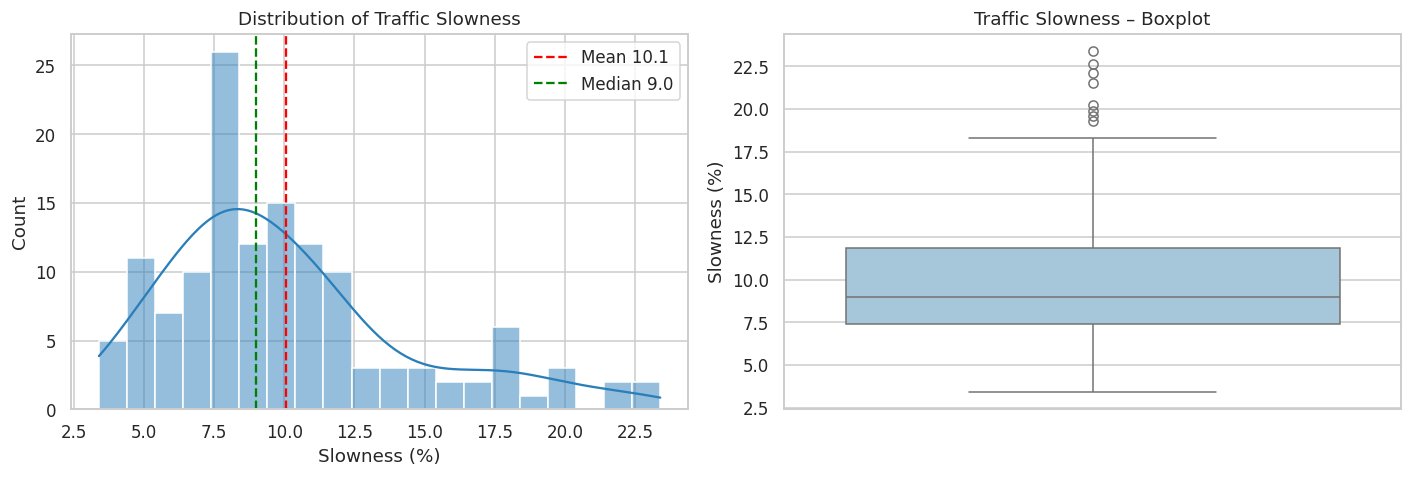

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df[TARGET], kde=True, bins=20, color="#2a7fba", ax=axes[0])
axes[0].axvline(df[TARGET].mean(),   color="red",   ls="--", label=f"Mean {df[TARGET].mean():.1f}")
axes[0].axvline(df[TARGET].median(), color="green", ls="--", label=f"Median {df[TARGET].median():.1f}")
axes[0].set_title("Distribution of Traffic Slowness"); axes[0].set_xlabel("Slowness (%)"); axes[0].legend()

sns.boxplot(y=df[TARGET], color="#9ecae1", ax=axes[1])
axes[1].set_title("Traffic Slowness – Boxplot"); axes[1].set_ylabel("Slowness (%)")
plt.tight_layout(); plt.show()

### 6.2 Distribution of every incident variable

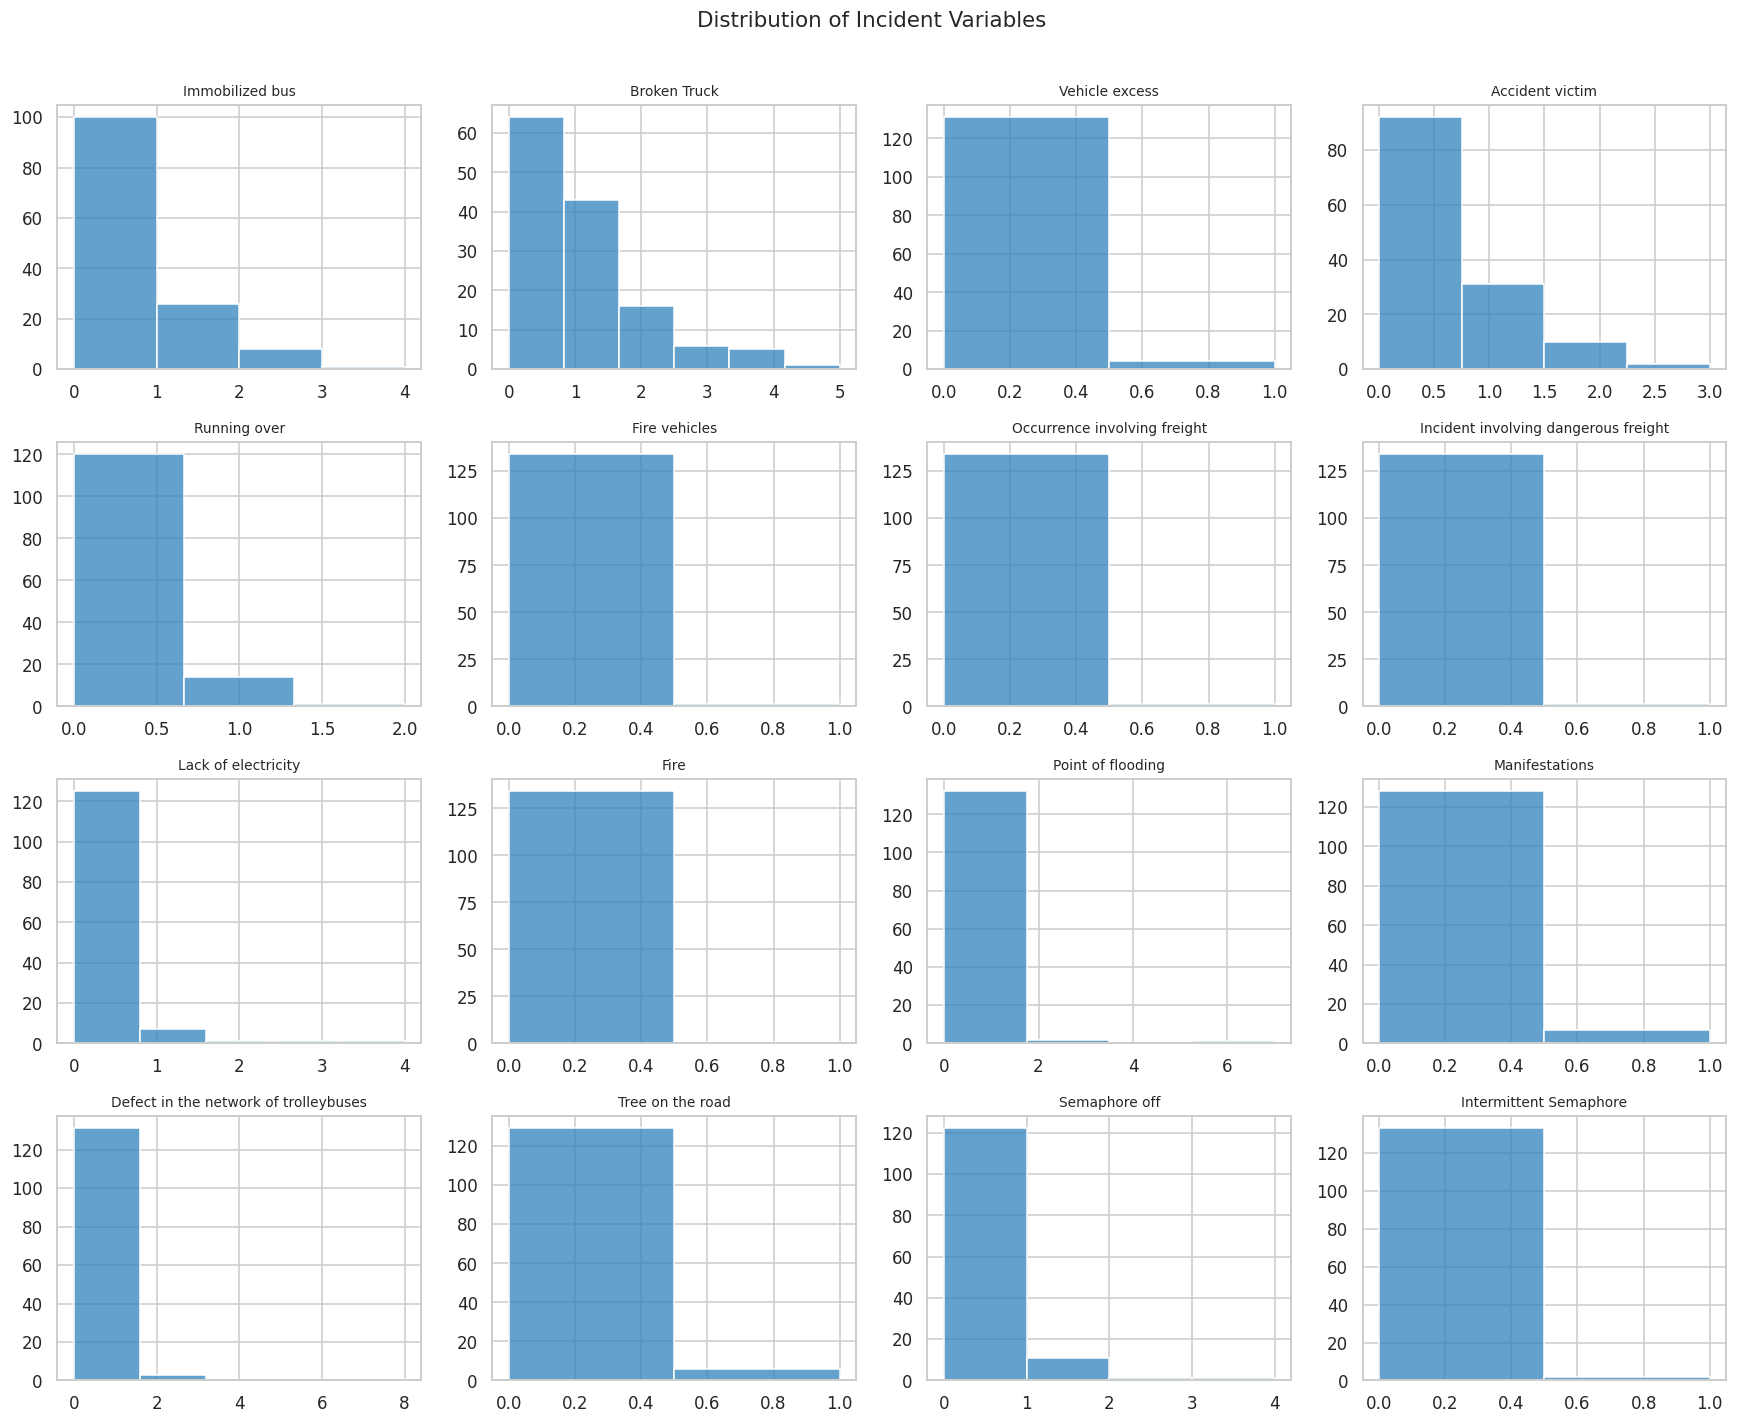

In [14]:
n = len(INCIDENTS); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 3.2 * rows))
for ax, c in zip(axes.ravel(), INCIDENTS):
    sns.histplot(df[c], bins=min(15, max(df[c].nunique(), 2)), color="#3182bd", ax=ax)
    ax.set_title(c.replace("_", " "), fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.suptitle("Distribution of Incident Variables", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

## 7. Time-Based Analysis
### 7.1 Average slowness by time of day

,Hour_code,Time,mean,std,min,max
0,1,07:00,3.96,0.62,3.4,4.9
1,2,07:30,5.34,1.13,3.8,6.6
2,3,08:00,6.64,1.59,5.3,8.7
3,4,08:30,7.32,1.88,5.6,9.5
4,5,09:00,9.02,1.66,7.0,11.1
5,6,09:30,8.88,1.44,7.4,10.9
6,7,10:00,8.02,1.41,6.2,10.1
7,8,10:30,7.86,1.54,6.5,10.3
8,9,11:00,8.18,1.62,6.7,10.9
9,10,11:30,8.52,2.24,6.4,12.3


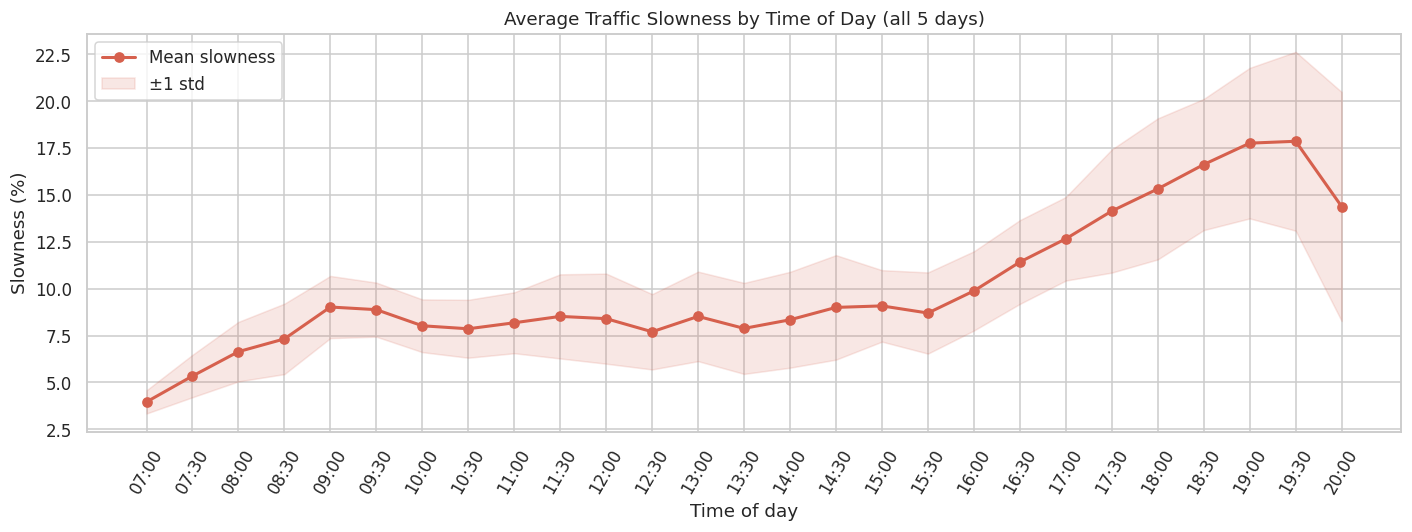

🔺 Highest average slowness: 19:30  (17.86%)
🔻 Lowest  average slowness: 07:00  (3.96%)


In [15]:
by_time = df.groupby(["Hour_code", "Time"])[TARGET].agg(["mean", "std", "min", "max"]).reset_index()
display(by_time.round(2).head(27))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(by_time["Time"], by_time["mean"], marker="o", color="#d6604d", lw=2, label="Mean slowness")
ax.fill_between(by_time["Time"],
                by_time["mean"] - by_time["std"].fillna(0),
                by_time["mean"] + by_time["std"].fillna(0), color="#d6604d", alpha=0.15, label="±1 std")
ax.set_title("Average Traffic Slowness by Time of Day (all 5 days)")
ax.set_xlabel("Time of day"); ax.set_ylabel("Slowness (%)")
plt.xticks(rotation=60); ax.legend(); plt.tight_layout(); plt.show()

peak = by_time.loc[by_time["mean"].idxmax()]
low  = by_time.loc[by_time["mean"].idxmin()]
print(f"🔺 Highest average slowness: {peak['Time']}  ({peak['mean']:.2f}%)")
print(f"🔻 Lowest  average slowness: {low['Time']}  ({low['mean']:.2f}%)")

### 7.2 Slowness profile for each weekday

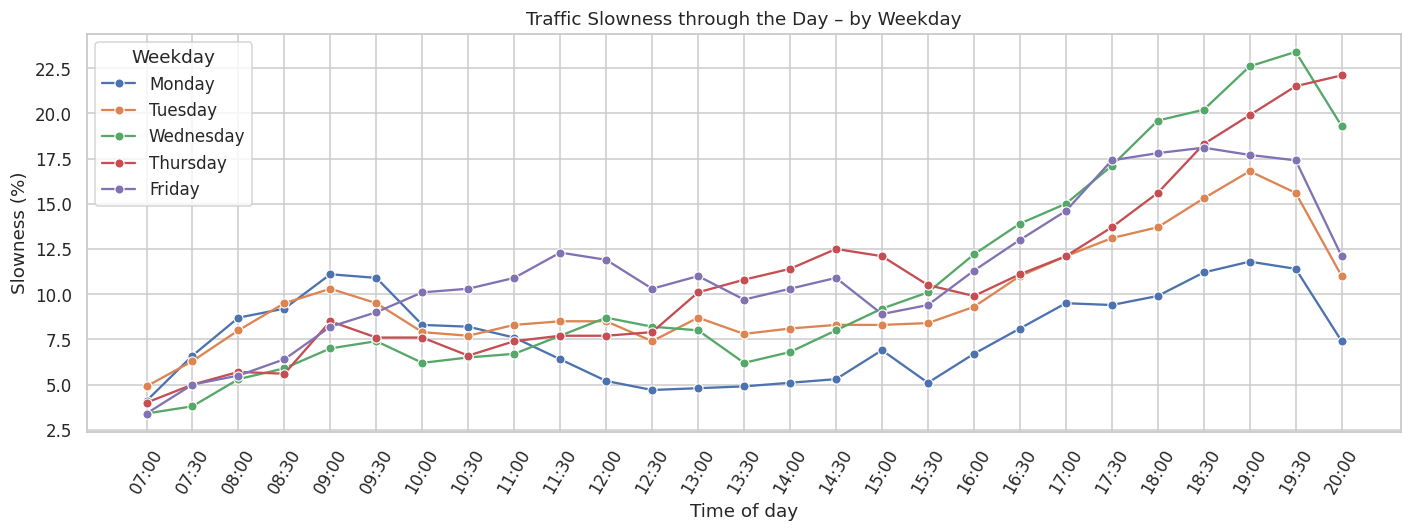

In [16]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=df, x="Time", y=TARGET, hue="Weekday", hue_order=weekdays, marker="o", ax=ax)
ax.set_title("Traffic Slowness through the Day – by Weekday")
ax.set_xlabel("Time of day"); ax.set_ylabel("Slowness (%)")
plt.xticks(rotation=60); plt.tight_layout(); plt.show()

### 7.3 Heatmap: weekday × time

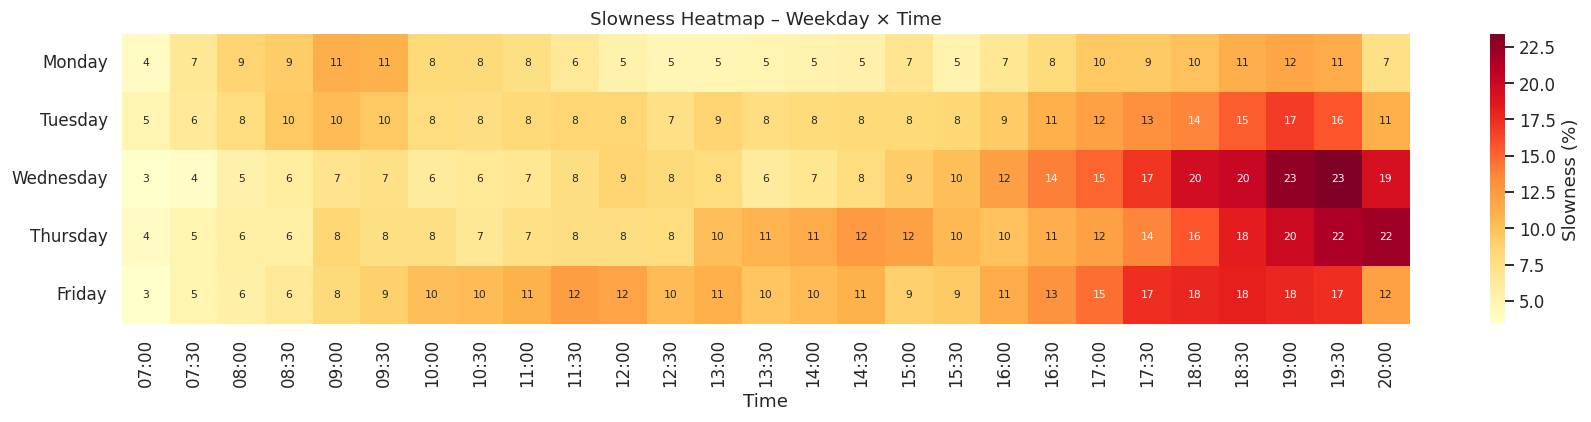

In [17]:
pivot = df.pivot_table(index="Weekday", columns="Time", values=TARGET, aggfunc="mean").reindex(weekdays)
plt.figure(figsize=(16, 4))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "Slowness (%)"})
plt.title("Slowness Heatmap – Weekday × Time"); plt.xlabel("Time"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 7.4 Differences between time periods and weekdays

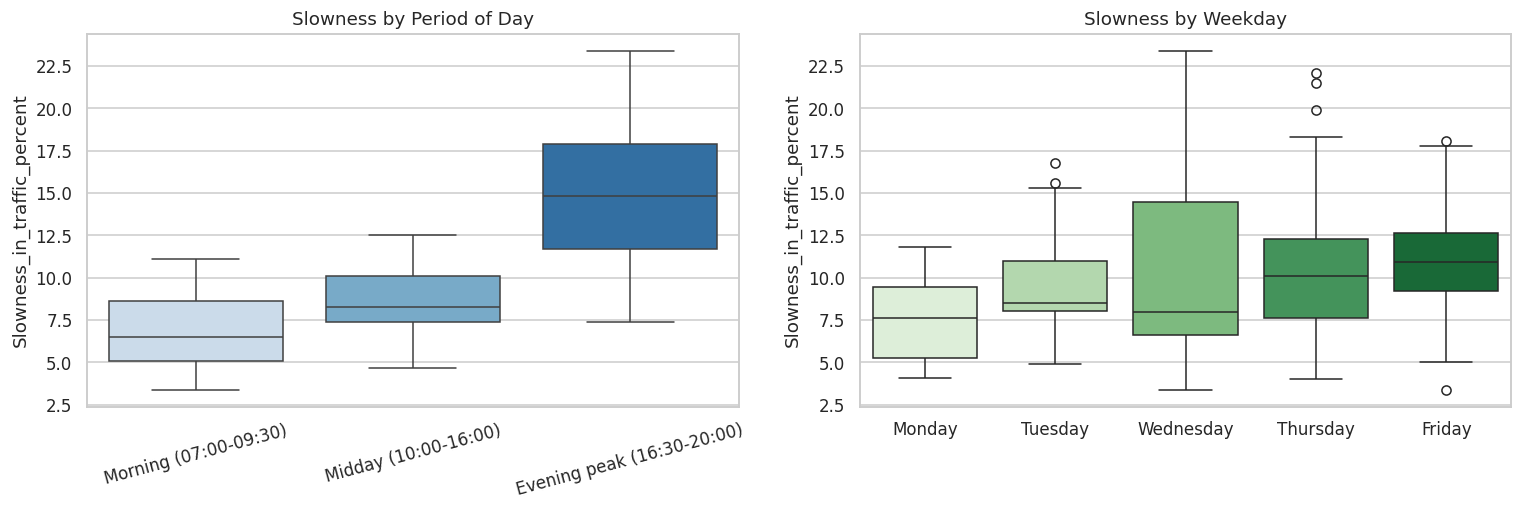

Mean slowness by period:


,count,mean,median,max
Period,,,,
Morning (07:00-09:30),30,6.86,6.5,11.1
Midday (10:00-16:00),65,8.47,8.3,12.5
Evening peak (16:30-20:00),40,15.02,14.8,23.4


Mean slowness by weekday:


,count,mean,median,max
Weekday,,,,
Monday,27,7.72,7.6,11.8
Tuesday,27,9.79,8.5,16.8
Wednesday,27,10.68,8.0,23.4
Thursday,27,10.85,10.1,22.1
Friday,27,11.22,10.9,18.1


Kruskal-Wallis across periods: H = 70.13, p = 0.0000
Kruskal-Wallis across weekdays: H = 12.67, p = 0.0130


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df, x="Period", y=TARGET, order=period_order, palette="Blues", ax=axes[0])
axes[0].set_title("Slowness by Period of Day"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=df, x="Weekday", y=TARGET, order=weekdays, palette="Greens", ax=axes[1])
axes[1].set_title("Slowness by Weekday"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

print("Mean slowness by period:");  display(df.groupby("Period")[TARGET].agg(["count", "mean", "median", "max"]).reindex(period_order).round(2))
print("Mean slowness by weekday:");  display(df.groupby("Weekday")[TARGET].agg(["count", "mean", "median", "max"]).reindex(weekdays).round(2))

# Statistical tests (small sample → interpret with care)
groups = [g[TARGET].values for _, g in df.groupby("Period")]
H, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis across periods: H = {H:.2f}, p = {p:.4f}")
groups = [g[TARGET].values for _, g in df.groupby("Weekday")]
H, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis across weekdays: H = {H:.2f}, p = {p:.4f}")

## 8. Incident Frequency Analysis

,Total_occurrences,Observations_with_incident,Pct_of_observations
Broken_Truck,118,71,52.6
Accident_victim,57,43,31.9
Immobilized_bus,46,35,25.9
Defect_in_the_network_of_trolleybuses,31,20,14.8
Semaphore_off,17,13,9.6
Lack_of_electricity,16,10,7.4
Point_of_flooding,16,6,4.4
Running_over,16,15,11.1
Manifestations,7,7,5.2
Tree_on_the_road,6,6,4.4


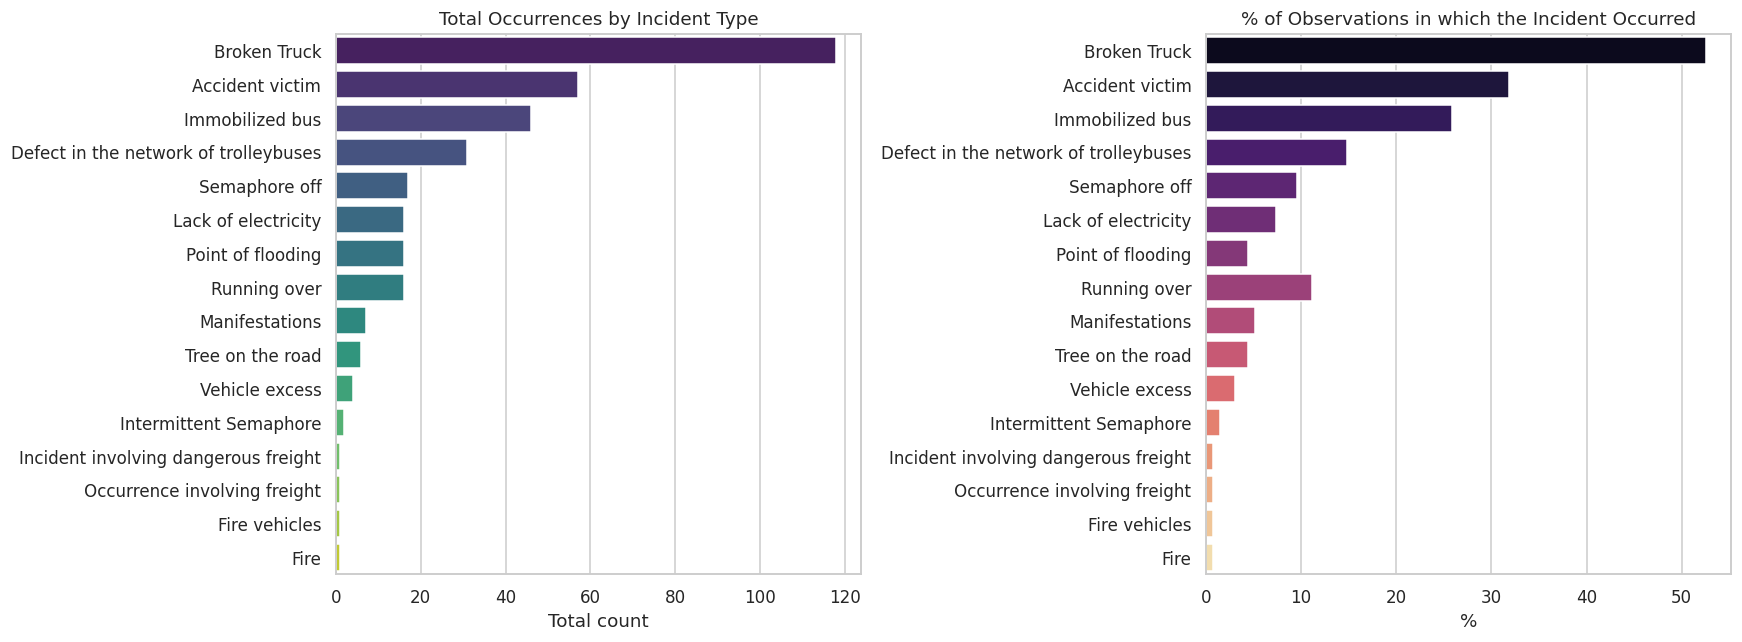

Most frequent incident: Broken Truck → 118 occurrences


In [19]:
total_events = df[INCIDENTS].sum().sort_values(ascending=False)
obs_with     = (df[INCIDENTS] > 0).sum().reindex(total_events.index)
freq = pd.DataFrame({"Total_occurrences": total_events,
                     "Observations_with_incident": obs_with,
                     "Pct_of_observations": (obs_with / len(df) * 100).round(1)})
display(freq)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=total_events.values, y=[c.replace("_", " ") for c in total_events.index],
            palette="viridis", ax=axes[0])
axes[0].set_title("Total Occurrences by Incident Type"); axes[0].set_xlabel("Total count")
sns.barplot(x=freq["Pct_of_observations"].values, y=[c.replace("_", " ") for c in freq.index],
            palette="magma", ax=axes[1])
axes[1].set_title("% of Observations in which the Incident Occurred"); axes[1].set_xlabel("%")
plt.tight_layout(); plt.show()
print("Most frequent incident:", total_events.index[0].replace("_", " "), "→", int(total_events.iloc[0]), "occurrences")

### 8.1 When do incidents happen? (total incidents per time slot)

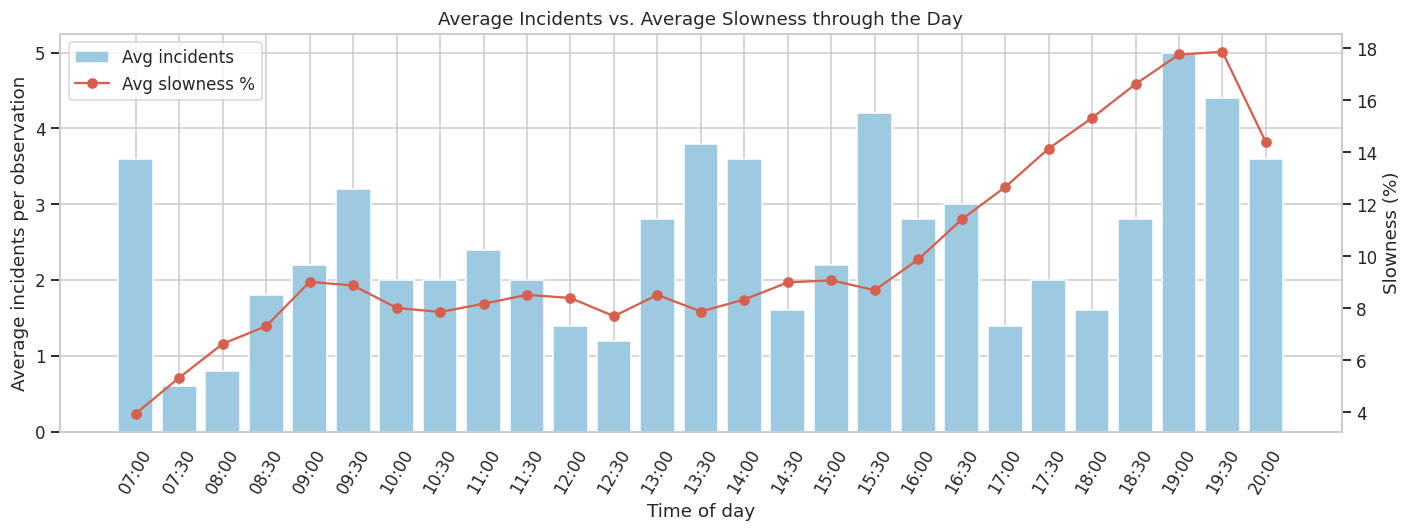

In [20]:
df["Total_incidents"] = df[INCIDENTS].sum(axis=1)
inc_time = df.groupby("Time")["Total_incidents"].mean()
slow_time = df.groupby("Time")[TARGET].mean()

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(inc_time.index, inc_time.values, color="#9ecae1", label="Avg incidents")
ax1.set_ylabel("Average incidents per observation"); ax1.set_xlabel("Time of day")
ax2 = ax1.twinx()
ax2.plot(slow_time.index, slow_time.values, color="#d6604d", marker="o", label="Avg slowness %")
ax2.set_ylabel("Slowness (%)"); ax2.grid(False)
plt.title("Average Incidents vs. Average Slowness through the Day")
ax1.tick_params(axis="x", rotation=60)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left"); plt.tight_layout(); plt.show()

## 9. Relationship Analysis – Incidents vs. Traffic Slowness
### 9.1 Scatter plots of the most related incidents

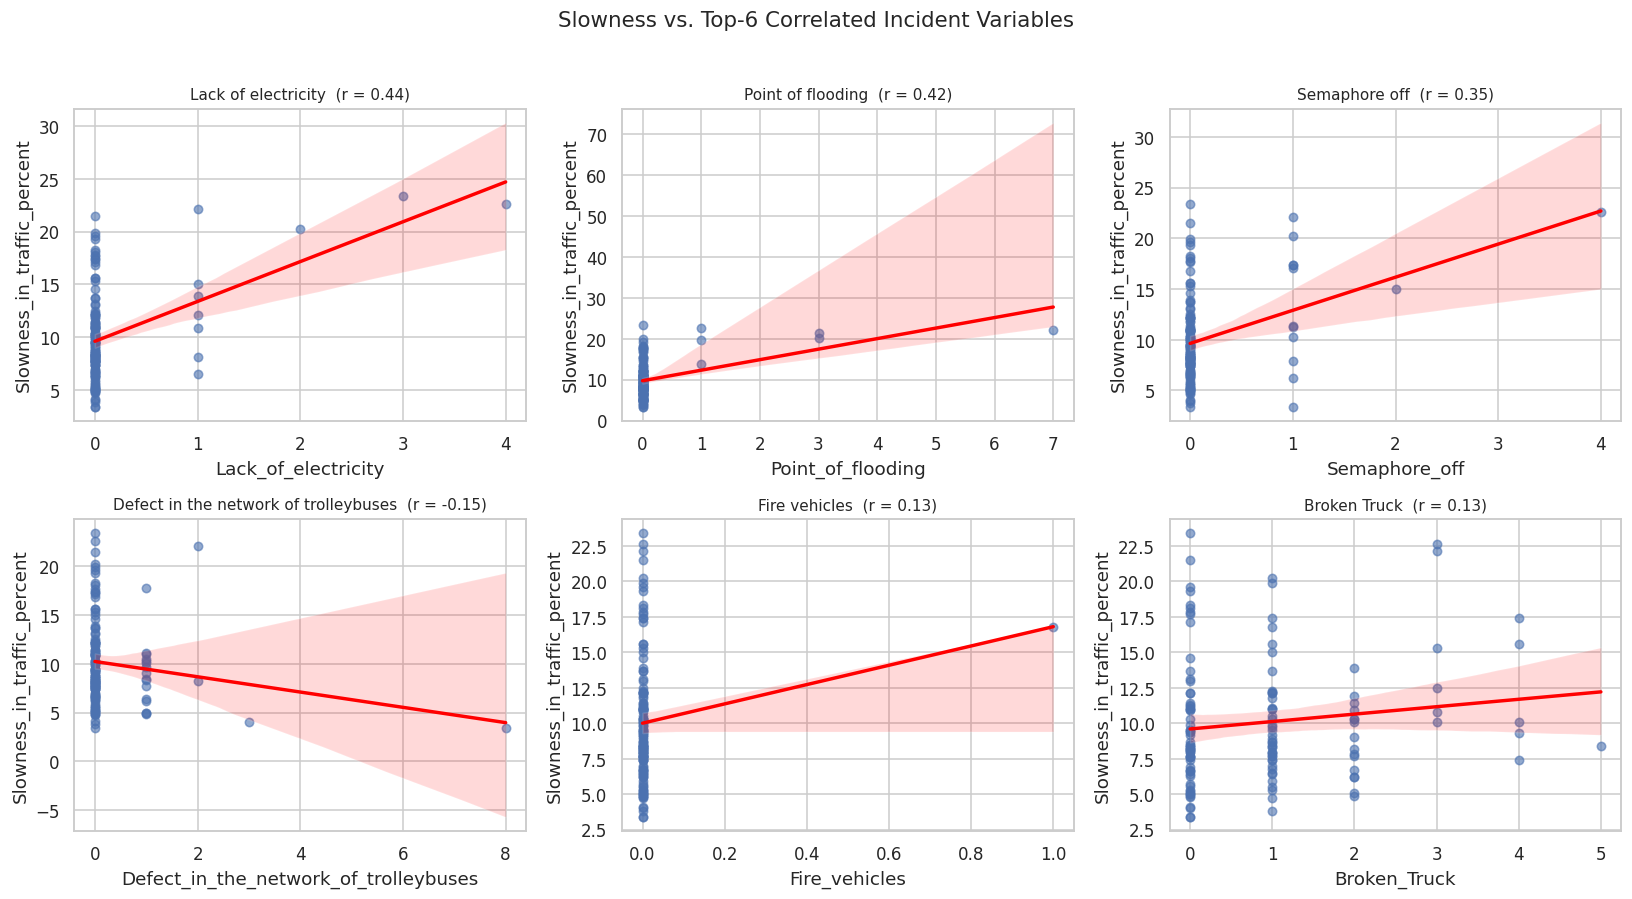

In [21]:
corr_target = df[INCIDENTS].corrwith(df[TARGET]).sort_values(key=abs, ascending=False)
top = corr_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), top):
    sns.regplot(data=df, x=c, y=TARGET, scatter_kws={"alpha": 0.6, "s": 30}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{c.replace('_',' ')}  (r = {corr_target[c]:.2f})", fontsize=10)
plt.suptitle("Slowness vs. Top-6 Correlated Incident Variables", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

### 9.2 Slowness when an incident is present vs. absent

,Incident,n_present,mean_slowness_present,mean_slowness_absent,difference,p_value (Mann-Whitney)
0,Point_of_flooding,6,19.983,9.590,10.393,0.000
1,Fire_vehicles,1,16.800,10.001,6.799,NaN
2,Lack_of_electricity,10,15.480,9.618,5.862,0.003
3,Semaphore_off,13,14.023,9.629,4.394,0.010
4,Immobilized_bus,35,11.363,9.593,1.770,0.048
5,Occurrence_involving_freight,1,11.400,10.042,1.358,NaN
6,Manifestations,7,11.286,9.984,1.301,0.732
7,Accident_victim,43,10.870,9.670,1.200,0.064
8,Broken_Truck,71,10.293,9.784,0.509,0.257
9,Running_over,15,10.193,10.034,0.159,0.801


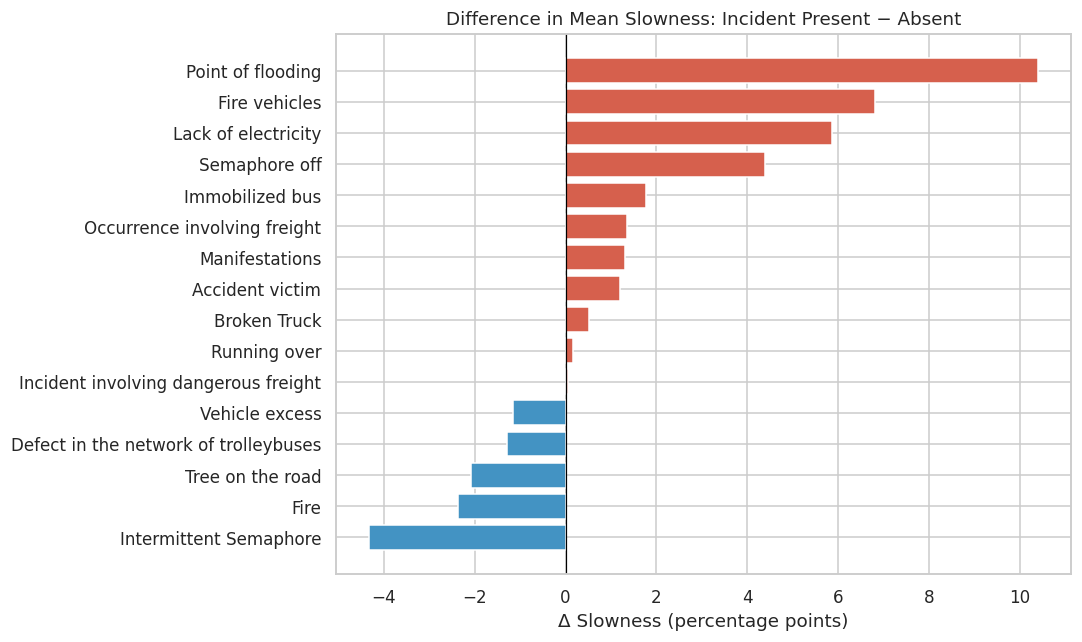

In [22]:
rows = []
for c in INCIDENTS:
    present = df.loc[df[c] > 0, TARGET]
    absent  = df.loc[df[c] == 0, TARGET]
    if len(present) >= 3 and len(absent) >= 3:
        u, p = stats.mannwhitneyu(present, absent, alternative="two-sided")
    else:
        p = np.nan
    rows.append({"Incident": c, "n_present": len(present), "mean_slowness_present": present.mean(),
                 "mean_slowness_absent": absent.mean(),
                 "difference": present.mean() - absent.mean() if len(present) else np.nan,
                 "p_value (Mann-Whitney)": p})
present_absent = pd.DataFrame(rows).sort_values("difference", ascending=False)
display(present_absent.round(3).reset_index(drop=True))

plot_df = present_absent.dropna(subset=["difference"])
plt.figure(figsize=(10, 6))
colors = ["#d6604d" if v > 0 else "#4393c3" for v in plot_df["difference"]]
plt.barh(plot_df["Incident"].str.replace("_", " "), plot_df["difference"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Difference in Mean Slowness: Incident Present − Absent")
plt.xlabel("Δ Slowness (percentage points)"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

### 9.3 Focus questions from the lab

Traffic-signal problems: 15 observations with incident  vs  120 without
   mean slowness WITH: 12.93%   WITHOUT: 9.69%   (Δ = +3.23)

Flooding: 6 observations with incident  vs  129 without
   mean slowness WITH: 19.98%   WITHOUT: 9.59%   (Δ = +10.39)

Accident-related: 50 observations with incident  vs  85 without
   mean slowness WITH: 10.65%   WITHOUT: 9.70%   (Δ = +0.95)

Breakdowns (bus / truck / trolleybus): 88 observations with incident  vs  47 without
   mean slowness WITH: 10.36%   WITHOUT: 9.47%   (Δ = +0.89)



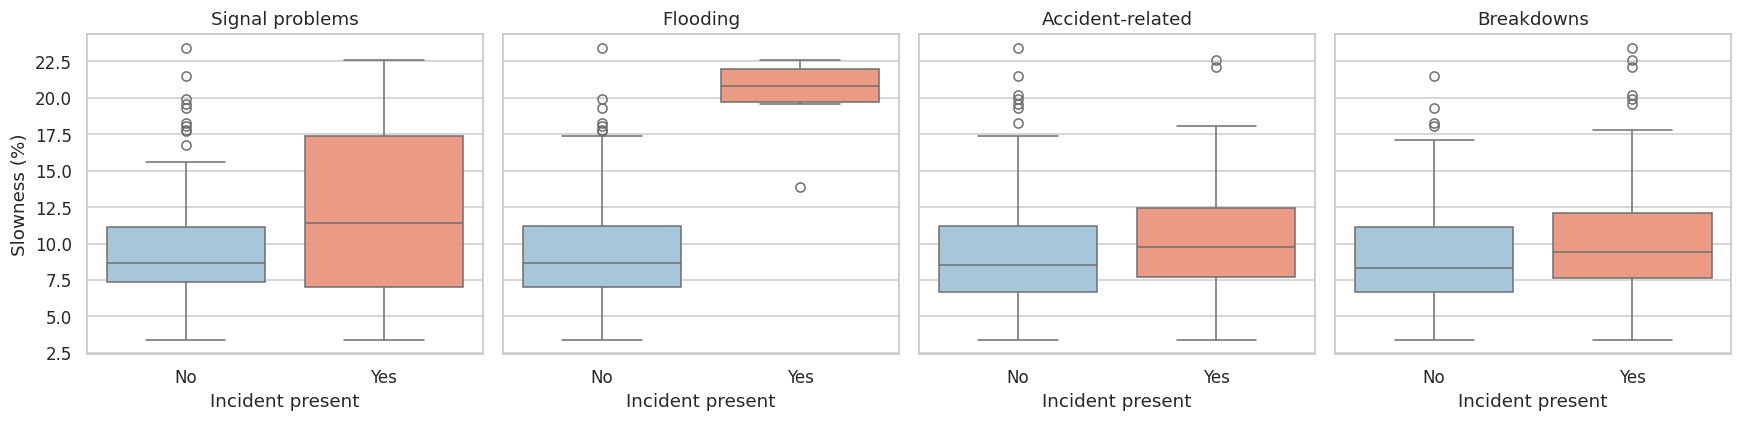

In [23]:
def compare(cols, label):
    cols = [c for c in cols if c in df.columns]
    mask = (df[cols] > 0).any(axis=1)
    a, b = df.loc[mask, TARGET], df.loc[~mask, TARGET]
    print(f"{label}: {mask.sum()} observations with incident  vs  {(~mask).sum()} without")
    print(f"   mean slowness WITH: {a.mean():.2f}%   WITHOUT: {b.mean():.2f}%   (Δ = {a.mean()-b.mean():+.2f})\n")
    return mask

m1 = compare(["Semaphore_off", "Intermittent_Semaphore"], "Traffic-signal problems")
m2 = compare(["Point_of_flooding"], "Flooding")
m3 = compare(["Accident_victim", "Running_over"], "Accident-related")
m4 = compare(["Immobilized_bus", "Broken_Truck", "Defect_in_the_network_of_trolleybuses"], "Breakdowns (bus / truck / trolleybus)")

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (mask, title) in zip(axes, [(m1, "Signal problems"), (m2, "Flooding"), (m3, "Accident-related"), (m4, "Breakdowns")]):
    tmp = pd.DataFrame({"Incident present": np.where(mask, "Yes", "No"), TARGET: df[TARGET]})
    sns.boxplot(data=tmp, x="Incident present", y=TARGET, order=["No", "Yes"], palette=["#9ecae1", "#fc9272"], ax=ax)
    ax.set_title(title)
axes[0].set_ylabel("Slowness (%)")
plt.tight_layout(); plt.show()

## 10. Correlation Analysis

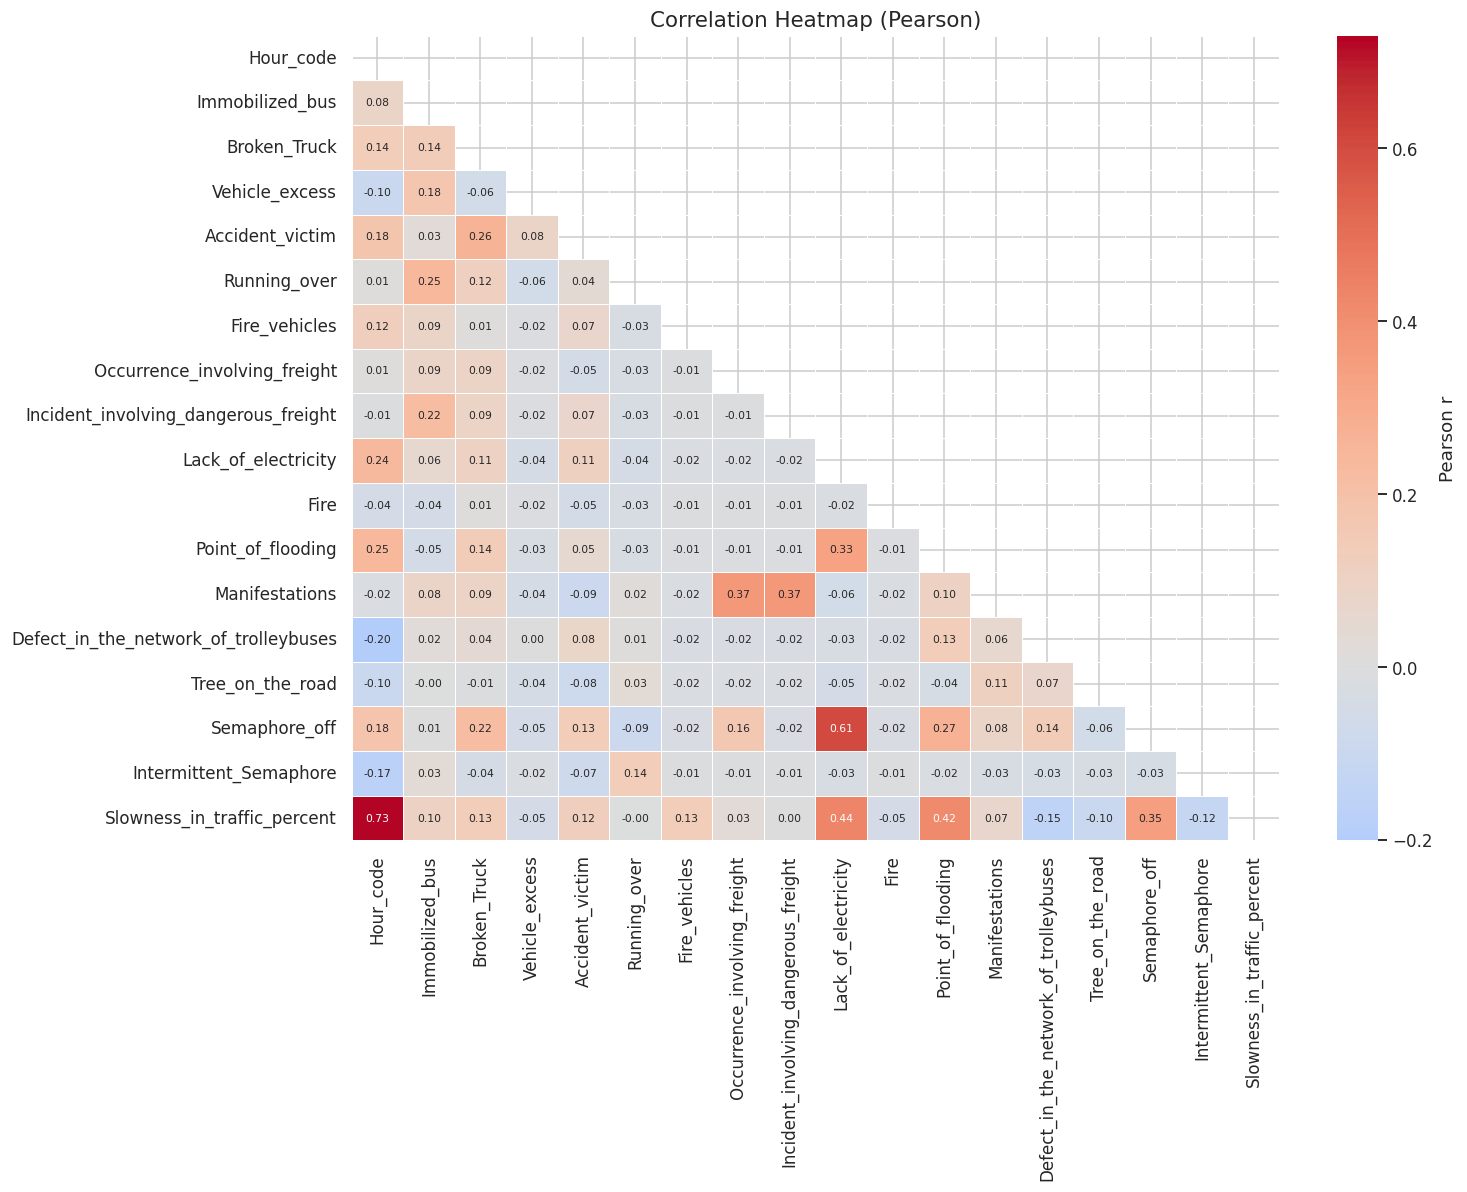

In [24]:
corr = df[["Hour_code"] + INCIDENTS + [TARGET]].corr()
plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.4, cbar_kws={"label": "Pearson r"})
plt.title("Correlation Heatmap (Pearson)", fontsize=14)
plt.tight_layout(); plt.show()

,Pearson,Spearman
Hour_code,0.730,0.724
Lack_of_electricity,0.437,0.262
Point_of_flooding,0.420,0.337
Semaphore_off,0.347,0.228
Defect_in_the_network_of_trolleybuses,-0.147,-0.122
Fire_vehicles,0.134,0.115
Broken_Truck,0.132,0.126
Accident_victim,0.122,0.161
Intermittent_Semaphore,-0.120,-0.153
Immobilized_bus,0.101,0.160


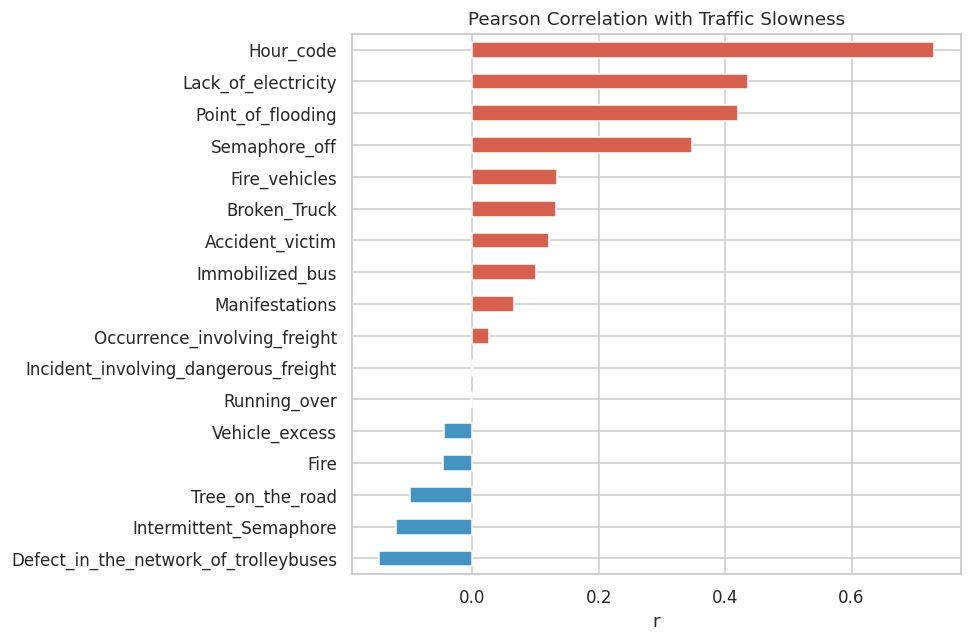

In [25]:
pear  = df[INCIDENTS + ["Hour_code"]].corrwith(df[TARGET])
spear = df[INCIDENTS + ["Hour_code"]].corrwith(df[TARGET], method="spearman")
corr_table = pd.DataFrame({"Pearson": pear, "Spearman": spear}).sort_values("Pearson", key=abs, ascending=False)
display(corr_table.round(3))

ax = corr_table["Pearson"].sort_values().plot(kind="barh", figsize=(9, 6),
        color=["#d6604d" if v > 0 else "#4393c3" for v in corr_table["Pearson"].sort_values()])
ax.set_title("Pearson Correlation with Traffic Slowness"); ax.set_xlabel("r")
plt.tight_layout(); plt.show()

> ⚠️ **Correlation ≠ causation.** With only 135 observations, a handful of days and time slots that move together, these relationships are *associations* worth investigating – not proof that an incident causes slowness.

## 11. Outlier Analysis (IQR Method)
We **flag** unusual observations but do **not** delete them – they may be genuine traffic events.

In [26]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, s[(s < lo) | (s > hi)]

lo, hi, out = iqr_outliers(df[TARGET])
print(f"Traffic slowness: IQR bounds = [{lo:.2f}, {hi:.2f}]  →  {len(out)} outlier(s)")
if len(out):
    display(df.loc[out.index, ["Weekday", "Time", TARGET, "Total_incidents"]])

rows = []
for c in INCIDENTS:
    l, h, o = iqr_outliers(df[c])
    rows.append({"Variable": c, "Q1": df[c].quantile(.25), "Q3": df[c].quantile(.75),
                 "Upper_bound": h, "n_outliers": len(o), "max": df[c].max()})
out_table = pd.DataFrame(rows).sort_values("n_outliers", ascending=False)
display(out_table.round(2).reset_index(drop=True))

Traffic slowness: IQR bounds = [0.72, 18.53]  →  8 outlier(s)


,Weekday,Time,Slowness_in_traffic_percent,Total_incidents
76,Wednesday,18:00,19.6,2
77,Wednesday,18:30,20.2,7
78,Wednesday,19:00,22.6,15
79,Wednesday,19:30,23.4,4
80,Wednesday,20:00,19.3,0
105,Thursday,19:00,19.9,1
106,Thursday,19:30,21.5,4
107,Thursday,20:00,22.1,15


,Variable,Q1,Q3,Upper_bound,n_outliers,max
0,Defect_in_the_network_of_trolleybuses,0.0,0.0,0.0,20,8
1,Running_over,0.0,0.0,0.0,15,2
2,Semaphore_off,0.0,0.0,0.0,13,4
3,Broken_Truck,0.0,1.0,2.5,12,5
4,Lack_of_electricity,0.0,0.0,0.0,10,4
5,Manifestations,0.0,0.0,0.0,7,1
6,Point_of_flooding,0.0,0.0,0.0,6,7
7,Tree_on_the_road,0.0,0.0,0.0,6,1
8,Vehicle_excess,0.0,0.0,0.0,4,1
9,Accident_victim,0.0,1.0,2.5,2,3


In [ ]:
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.boxplot(data=df[INCIDENTS], orient="v", palette="Set3", ax=ax)
ax.set_xticklabels([c.replace("_", "\n") for c in INCIDENTS], rotation=90, fontsize=7)
ax.set_title("Boxplots of Incident Variables"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

## 12. Highest and Lowest Slowness Observations

In [27]:
show_cols = ["Weekday", "Time", TARGET, "Total_incidents"] + INCIDENTS
print("🔺 Top 10 most congested observations")
display(df.sort_values(TARGET, ascending=False).head(10)[show_cols])
print("🔻 Bottom 10 (smoothest) observations")
display(df.sort_values(TARGET, ascending=True).head(10)[show_cols])

🔺 Top 10 most congested observations


,Weekday,Time,Slowness_in_traffic_percent,Total_incidents,Immobilized_bus,Broken_Truck,Vehicle_excess,Accident_victim,Running_over,Fire_vehicles,Occurrence_involving_freight,Incident_involving_dangerous_freight,Lack_of_electricity,Fire,Point_of_flooding,Manifestations,Defect_in_the_network_of_trolleybuses,Tree_on_the_road,Semaphore_off,Intermittent_Semaphore
79,Wednesday,19:30,23.4,4,1,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0
78,Wednesday,19:00,22.6,15,1,3,0,2,0,0,0,0,4,0,1,0,0,0,4,0
107,Thursday,20:00,22.1,15,0,3,0,1,0,0,0,0,1,0,7,0,2,0,1,0
106,Thursday,19:30,21.5,4,0,0,0,0,0,0,0,0,0,0,3,1,0,0,0,0
77,Wednesday,18:30,20.2,7,0,1,0,0,0,0,0,0,2,0,3,0,0,0,1,0
105,Thursday,19:00,19.9,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
76,Wednesday,18:00,19.6,2,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
80,Wednesday,20:00,19.3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
104,Thursday,18:30,18.3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
131,Friday,18:30,18.1,2,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0


🔻 Bottom 10 (smoothest) observations


,Weekday,Time,Slowness_in_traffic_percent,Total_incidents,Immobilized_bus,Broken_Truck,Vehicle_excess,Accident_victim,Running_over,Fire_vehicles,Occurrence_involving_freight,Incident_involving_dangerous_freight,Lack_of_electricity,Fire,Point_of_flooding,Manifestations,Defect_in_the_network_of_trolleybuses,Tree_on_the_road,Semaphore_off,Intermittent_Semaphore
54,Wednesday,07:00,3.4,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
108,Friday,07:00,3.4,10,0,0,0,1,0,0,0,0,0,0,0,0,8,0,1,0
55,Wednesday,07:30,3.8,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
81,Thursday,07:00,4.0,4,0,0,0,0,0,0,0,0,0,0,0,1,3,0,0,0
0,Monday,07:00,4.1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11,Monday,12:30,4.7,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12,Monday,13:00,4.8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
13,Monday,13:30,4.9,5,2,2,0,1,0,0,0,0,0,0,0,0,0,0,0,0
27,Tuesday,07:00,4.9,3,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0
109,Friday,07:30,5.0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


## 13. Bonus – Simple Predictive Baseline
EDA is the first step before modeling. This quick baseline checks how much of the slowness can be explained by time and incidents.

Ridge regression    R² = 0.525 (±0.191)   MAE = 2.25 pp
Random forest       R² = 0.553 (±0.086)   MAE = 2.21 pp


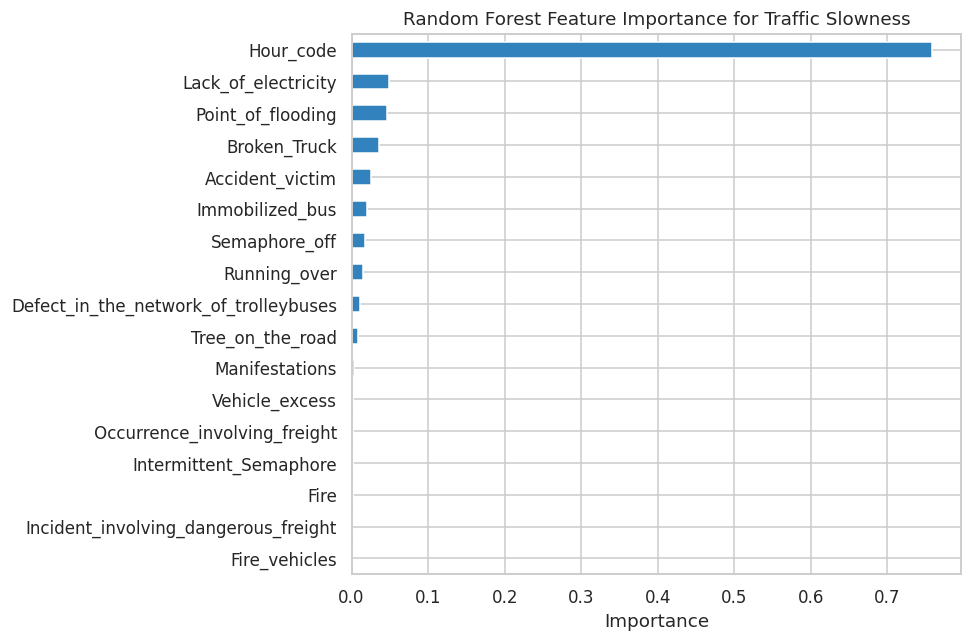

In [28]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = ["Hour_code"] + INCIDENTS
X, y = df[features], df[TARGET]
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random forest":    RandomForestRegressor(n_estimators=300, random_state=42),
}
for name, m in models.items():
    r2  = cross_val_score(m, X, y, cv=cv, scoring="r2")
    mae = -cross_val_score(m, X, y, cv=cv, scoring="neg_mean_absolute_error")
    print(f"{name:18s}  R² = {r2.mean():.3f} (±{r2.std():.3f})   MAE = {mae.mean():.2f} pp")

rf = models["Random forest"].fit(X, y)
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(9, 6), color="#3182bd")
plt.title("Random Forest Feature Importance for Traffic Slowness"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()

## 14. Key Insights & Conclusion

In [29]:
# Data-driven summary generated from the results above
peak = by_time.loc[by_time["mean"].idxmax()]
low  = by_time.loc[by_time["mean"].idxmin()]
period_means = df.groupby("Period")[TARGET].mean().reindex(period_order)
day_means = df.groupby("Weekday")[TARGET].mean().reindex(weekdays)
top_inc = total_events.index[0].replace("_", " ")
pos = corr_table["Pearson"].drop("Hour_code", errors="ignore")
best_pos, best_neg = pos.idxmax(), pos.idxmin()

print("="*70)
print("KEY OBSERVATIONS FROM THE DATA")
print("="*70)
print(f"1. Dataset: {df.shape[0]} observations, {len(INCIDENTS)} incident variables + target. "
      f"Missing values: {int(df.isnull().sum().sum())}, duplicates: {int(df.duplicated().sum())}.")
print(f"2. Slowness averages {df[TARGET].mean():.1f}% (median {df[TARGET].median():.1f}%), "
      f"ranging from {df[TARGET].min():.1f}% to {df[TARGET].max():.1f}%.")
print(f"3. Highest average slowness at {peak['Time']} ({peak['mean']:.1f}%); lowest at {low['Time']} ({low['mean']:.1f}%).")
print(f"4. By period: " + "; ".join(f"{k.split(' (')[0]} {v:.1f}%" for k, v in period_means.items()) + ".")
print(f"5. Busiest weekday (avg slowness): {day_means.idxmax()} ({day_means.max():.1f}%); "
      f"calmest: {day_means.idxmin()} ({day_means.min():.1f}%).")
print(f"6. Most frequent incident type: {top_inc} ({int(total_events.iloc[0])} occurrences).")
print(f"7. Strongest positive correlation with slowness: {best_pos.replace('_',' ')} (r = {pos[best_pos]:.2f}); "
      f"strongest negative: {best_neg.replace('_',' ')} (r = {pos[best_neg]:.2f}).")
print(f"8. IQR outliers in slowness: {len(out)}. These are kept in the data – they should be investigated, not deleted.")
print("="*70)

KEY OBSERVATIONS FROM THE DATA
1. Dataset: 135 observations, 16 incident variables + target. Missing values: 0, duplicates: 0.
2. Slowness averages 10.1% (median 9.0%), ranging from 3.4% to 23.4%.
3. Highest average slowness at 19:30 (17.9%); lowest at 07:00 (4.0%).
4. By period: Morning 6.9%; Midday 8.5%; Evening peak 15.0%.
5. Busiest weekday (avg slowness): Friday (11.2%); calmest: Monday (7.7%).
6. Most frequent incident type: Broken Truck (118 occurrences).
7. Strongest positive correlation with slowness: Lack of electricity (r = 0.44); strongest negative: Defect in the network of trolleybuses (r = -0.15).
8. IQR outliers in slowness: 8. These are kept in the data – they should be investigated, not deleted.


### Conclusion
- **Data quality:** the dataset is clean (no missing values) → only minimal validation and a time-conversion step were needed.
- **Time matters:** traffic slowness follows a clear time-of-day pattern with distinct congested and free-flowing periods (see sections 7.1–7.4).
- **Incidents:** some incident types are far more frequent than others; several show a positive association with slowness, particularly vehicle-breakdown and signal-related events (see sections 8–10).
- **Caution:** with 135 observations over 5 days, results are *exploratory*. They show associations, not causes.

### Possible next steps
- Collect data over more weeks and seasons, and add weather / event data.
- Build forecasting models (e.g. gradient boosting, time-series models) using this EDA as the foundation.
- Use findings to support traffic-signal maintenance, rapid breakdown-response and peak-hour planning.

### Reference
Ferreira, R., Martiniano, A., & Sassi, R. (2011). *Behavior of the urban traffic of the city of Sao Paulo in Brazil.* UCI Machine Learning Repository. https://doi.org/10.24432/C5902F